### Лабораторна робота №1. Використання бібліотек Pandas та Matplotlib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 1. Відкрити та зчитати файл з даними.
file_path = "Input_Lab-1_Vehicle_Sales.csv"
data = pd.read_csv(file_path)

In [3]:
# 2. Визначити та вивести кількість записів та кількість полів у кожному записі.
num_records = len(data)
num_fields = len(data.columns)

print(f"Кількість записів: {num_records}")
print(f"Кількість полів у кожному записі: {num_fields}")

Кількість записів: 186
Кількість полів у кожному записі: 6


In [4]:
# 3. Вивести K + 7 перших та 5 * K - 3 останніх записів.
K = 5
print("Перші 12 записів:")
print(data.head(K + 7))
print("\nОстанні 22 записи:")
print(data.tail(5 * K - 3))

Перші 12 записів:
    Year Month    New   Used Total Sales New Total Sales Used
0   2002   JAN  31106  49927      $755015820       $386481929
1   2002   FEB  27520  50982      $664454223       $361353242
2   2002   MAR  34225  58794      $805666244       $419385387
3   2002   APR  36452  59817      $846368297       $433061150
4   2002   MAY  37359  60577      $855005784       $442569410
5   2002   JUN  36348  55415      $830251613       $414731166
6   2002   JUL  30367  55235      $700530891       $384673023
7   2002   AUG  38965  60310      $934484212       $455453720
8   2002   SEP  39740  55485      $950502055       $432112270
9   2002   OCT  35276  58020      $865326154       $456738532
10  2002   NOV  27812  49066      $691740703       $379196575
11  2002   DEC  26994  42461      $673208880       $374453368

Останні 22 записи:
     Year Month    New   Used Total Sales New Total Sales Used
164  2015   SEP  32154  62182     $1035533325       $632452008
165  2015   OCT  30552  62954 

In [5]:
# 4. Визначити та вивести тип полів кожного запису.
print("\nТипи полів кожного запису:")
print(data.dtypes)


Типи полів кожного запису:
Year                 int64
Month               object
New                  int64
Used                 int64
Total Sales New     object
Total Sales Used    object
dtype: object


In [6]:
# 5. Привести поля, що відповідають обсягам продаж, до числового вигляду (показати, що це виконано).
# Перевірка типів даних до перетворення
print("\nТипи даних до перетворення:")
print(data['Total Sales New'].dtype)
print(data['Total Sales Used'].dtype)
print(f"Total Sales New: {data.loc[0,'Total Sales New']}")
print(f"Total Sales Used: {data.loc[0,'Total Sales Used']}")

# Перетворення полів до числового формату
data['Total Sales New'] = data['Total Sales New'].replace('[\$]', '', regex=True).astype(float)
data['Total Sales Used'] = data['Total Sales Used'].replace('[\$]', '', regex=True).astype(float)

# Перевірка типів даних після перетворення
print("\nТипи даних після перетворення:")
print(data['Total Sales New'].dtype)
print(data['Total Sales Used'].dtype)
print(f"Total Sales New: {data.loc[0,'Total Sales New']}")
print(f"Total Sales Used: {data.loc[0,'Total Sales Used']}")


Типи даних до перетворення:
object
object
Total Sales New: $755015820
Total Sales Used: $386481929

Типи даних після перетворення:
float64
float64
Total Sales New: 755015820.0
Total Sales Used: 386481929.0


In [7]:
# 6. Ввести нові поля:
# a. Сумарний обсяг продаж автомобілів (нових та б/в) у кожний період;
data['Total Sold Cars'] = data['New'] + data['Used']

# b. Сумарний дохід від продажу автомобілів (нових та б/в) у кожний період;
data['Total Revenue'] = data['Total Sales New'] + data['Total Sales Used']

# c. Різницю в обсязі продаж нових та б/в автомобілів у кожній період.
data['Total Sales Difference'] = data['Total Sales New'] - data['Total Sales Used']

In [8]:
print(data.tail(5))

     Year Month    New   Used  Total Sales New  Total Sales Used  \
181  2017   FEB  22413  55989     7.762220e+08       592255229.0   
182  2017   MAR  27838  72717     9.267031e+08       744746293.0   
183  2017   APR  26135  62740     8.677223e+08       654981615.0   
184  2017   MAY  28931  68296     9.378041e+08       718689038.0   
185  2017   JUN  31835  67827     1.019153e+09       720739448.0   

     Total Sold Cars  Total Revenue  Total Sales Difference  
181            78402   1.368477e+09             183966779.0  
182           100555   1.671449e+09             181956851.0  
183            88875   1.522704e+09             212740676.0  
184            97227   1.656493e+09             219115075.0  
185            99662   1.739893e+09             298414009.0  


In [9]:
# 7. Змінити порядок розташування полів
data = data[['Year', 'Month', 'Total Revenue', 'Total Sales New', 'Total Sales Used', 'Total Sold Cars', 'New', 'Used', 'Total Sales Difference']]

In [10]:
print(data.tail(5))

     Year Month  Total Revenue  Total Sales New  Total Sales Used  \
181  2017   FEB   1.368477e+09     7.762220e+08       592255229.0   
182  2017   MAR   1.671449e+09     9.267031e+08       744746293.0   
183  2017   APR   1.522704e+09     8.677223e+08       654981615.0   
184  2017   MAY   1.656493e+09     9.378041e+08       718689038.0   
185  2017   JUN   1.739893e+09     1.019153e+09       720739448.0   

     Total Sold Cars    New   Used  Total Sales Difference  
181            78402  22413  55989             183966779.0  
182           100555  27838  72717             181956851.0  
183            88875  26135  62740             212740676.0  
184            97227  28931  68296             219115075.0  
185            99662  31835  67827             298414009.0  


In [11]:
# 8. Визначити та вивести:
# a. Рік та місяць, у які нових автомобілів було продано менше за б/в;
min_new_sales_month = data[data['New'] < data['Used']][['Year', 'Month']]
print("Рік та місяць, у які нових автомобілів було продано менше за б/в:")
print(min_new_sales_month)

# b. Рік та місяць, коли сумарний дохід був мінімальним;
min_revenue_month = data[data['Total Revenue'] == data['Total Revenue'].min()][['Year', 'Month']]
print("\nРік та місяць, коли сумарний дохід був мінімальним:")
print(min_revenue_month)

# c. Рік та місяць, коли було продано найбільше б/в авто.
max_used_sales_month = data[data['Used'] == data['Used'].max()][['Year', 'Month']]
print("\nРік та місяць, коли було продано найбільше б/в авто:")
print(max_used_sales_month)

Рік та місяць, у які нових автомобілів було продано менше за б/в:
     Year Month
0    2002   JAN
1    2002   FEB
2    2002   MAR
3    2002   APR
4    2002   MAY
..    ...   ...
181  2017   FEB
182  2017   MAR
183  2017   APR
184  2017   MAY
185  2017   JUN

[186 rows x 2 columns]

Рік та місяць, коли сумарний дохід був мінімальним:
    Year Month
97  2010   FEB

Рік та місяць, коли було продано найбільше б/в авто:
     Year Month
170  2016   MAR


In [12]:
# 9. Визначити та вивести:
# a. Сумарний обсяг продажу транспортних засобів за кожен рік;
total_revenue_per_year = data.groupby('Year')['Total Revenue'].sum()

print(f'Сумарний обсяг продажу транспортних засобів за кожен рік: {total_revenue_per_year}')

# b. Середній дохід від продажу б/в транспортних засобів в місяці М, де М – це порядковий номер у списку підгрупи за абеткою.
M = '03'
import datetime
month = datetime.datetime(year=2024, month=int(M), day=1).strftime("%b").upper()

month_total_sales_used_mean = data.loc[data['Month'] == month, 'Total Sales Used'].mean()

print(f'Середній дохід від продажу б/в транспортних засобів в місяці {month}: ${month_total_sales_used_mean:.2f}')

Сумарний обсяг продажу транспортних засобів за кожен рік: Year
2002    1.451276e+10
2003    1.578922e+10
2004    1.635850e+10
2005    1.664654e+10
2006    1.627734e+10
2007    1.579213e+10
2008    1.287157e+10
2009    1.119626e+10
2010    1.251572e+10
2011    1.367681e+10
2012    1.486712e+10
2013    1.608962e+10
2014    1.692238e+10
2015    1.842278e+10
2016    1.953893e+10
2017    9.633381e+09
Name: Total Revenue, dtype: float64
Середній дохід від продажу б/в транспортних засобів в місяці MAR: $518439502.69


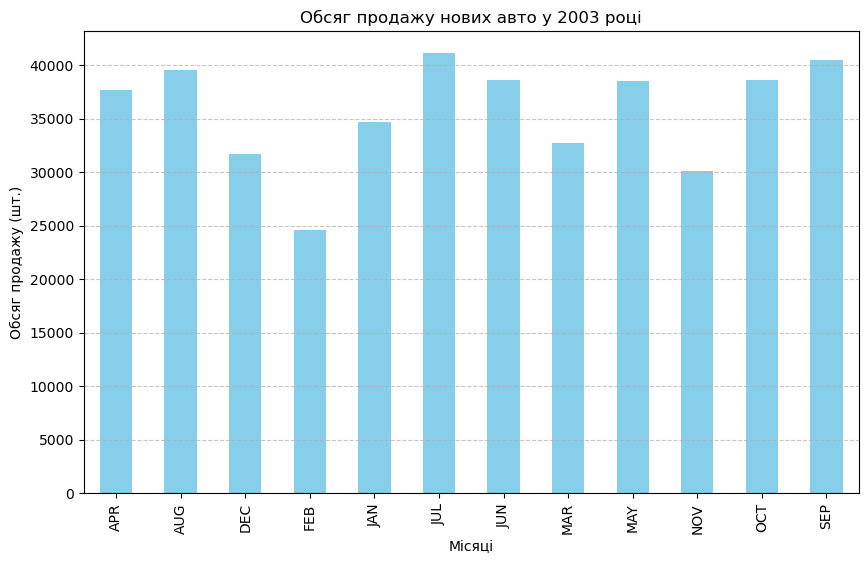

In [13]:
# 10. Побудувати стовпчикову діаграму обсягу продаж нових авто у році 20YY, де дві останні цифри року визначаються як 17 – порядковий номер у списку підгрупи за абеткою.

# Фільтрація даних за рік 20YY та типом авто "New"
sales_year_new = data.loc[data['Year'] == int('20' + M), ['New', 'Month']]
sales_year_new = sales_year_new.groupby('Month')['New'].sum()

# Побудова стовпчикової діаграми
plt.figure(figsize=(10, 6))
sales_year_new.plot(x='New', y='Month', kind='bar', color='skyblue')
plt.title(f'Обсяг продажу нових авто у 20{M} році')
plt.xlabel('Місяці')
plt.ylabel('Обсяг продажу (шт.)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

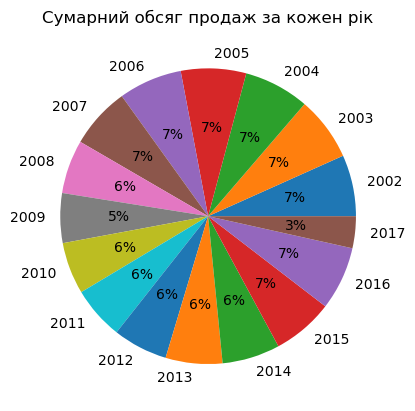

In [14]:
# 11. Побудувати кругову діаграму сумарного обсягу продаж за кожен рік.

# Розрахунок сумарного обсягу продаж за кожен рік
total_sold_cars_per_year = data.groupby('Year')['Total Sold Cars'].sum()

# Побудова кругової діаграми
total_sold_cars_per_year.plot(kind='pie', autopct='%1.0f%%', ylabel='')
plt.title('Сумарний обсяг продаж за кожен рік')
plt.show()

     Total Sales New  Total Sales Used
0       7.550158e+08       386481929.0
1       6.644542e+08       361353242.0
2       8.056662e+08       419385387.0
3       8.463683e+08       433061150.0
4       8.550058e+08       442569410.0
..               ...               ...
181     7.762220e+08       592255229.0
182     9.267031e+08       744746293.0
183     8.677223e+08       654981615.0
184     9.378041e+08       718689038.0
185     1.019153e+09       720739448.0

[186 rows x 2 columns]


<Figure size 640x480 with 0 Axes>

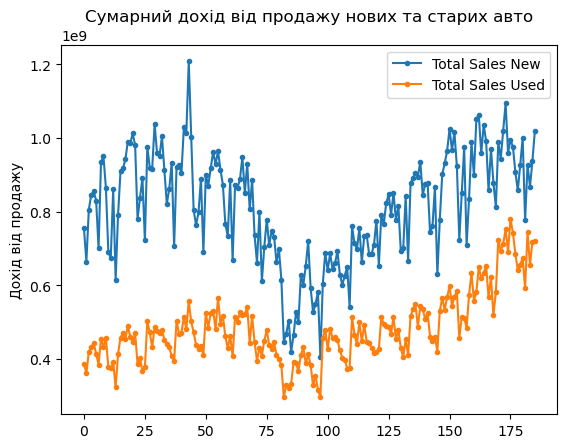

In [15]:
# 12. Побудувати на одному графіку:
# a. Сумарний дохід від продажу нових авто;
# b. Сумарний дохід від продажу старих авто.

total_revenue_new_used = data[['Total Sales New', 'Total Sales Used']]
print(total_revenue_new_used)
plt.figure();
total_revenue_new_used.plot(style='.-', xlabel='', ylabel='Дохід від продажу', title='Cумарний дохід від продажу нових та старих авто');